# Proyecto 2 — Aprendizaje No Supervisado: Agrupamiento con DBSCAN
## Segmentación de Estudiantes basada en Perfil Académico y Socioemocional
**Paquete B — Persona 2:** Modelado Espacial Basado en Densidad (DBSCAN)  
**Semestre:** Sexto Semestre — Inteligencia Artificial  
**Semilla de Reproducibilidad:** `RANDOM_STATE = 42`

---

### Índice del Cuaderno
1. [Contexto y Pregunta de Negocio](#1-contexto-y-pregunta-de-negocio)
2. [Carga de Cimientos y Análisis Exploratorio de Datos (EDA)](#2-carga-de-cimientos-y-análisis-exploratorio-de-datos-eda)
   - 2.1 Inspección y Matriz de Correlaciones
   - 2.2 Detección de Valores Atípicos y Densidad
   - 2.3 Análisis de Componentes Principales (PCA): Varianza y Loadings
3. [Selección Justificada de Hiperparámetros (MinPts y $\varepsilon$)](#3-selección-justificada-de-hiperparámetros-minpts-y-varepsilon)
   - 3.1 Regla heurística para MinPts
   - 3.2 Gráfico de distancia al $k$-ésimo vecino ($k$-dist graph)
   - 3.3 Barrido experimental de $\varepsilon$ y métricas
4. [Entrenamiento del Modelo DBSCAN y Reporte de Métricas](#4-entrenamiento-del-modelo-dbscan-y-reporte-de-métricas)
5. [Visualización en el Espacio Reducido PCA 2D](#5-visualización-en-el-espacio-reducido-pca-2d)
6. [Perfilamiento e Interpretación de Negocio](#6-perfilamiento-e-interpretación-de-negocio)
7. [Inferencia para Nuevos Registros con NearestNeighbors](#7-inferencia-para-nuevos-registros-con-nearestneighbors)
8. [Exportación Final de Artefactos](#8-exportación-final-de-artefactos)

---
> **Nota de Defensa Oral (Estándar PhishGuard):**  
> Cada sección cuenta con explicaciones teóricas previas y bloques posteriores de **`Interpretación y Argumento para Defensa`**. Estos bloques sintetizan la lógica matemática, las conclusiones del negocio y las respuestas preparadas ante preguntas habituales del jurado docente.


---
## 1. Contexto y Pregunta de Negocio

### ¿Qué problema aborda este modelado?
El objetivo fundamental es identificar patrones latentes de agrupación en una población universitaria de 800 estudiantes a partir de 16 variables multidimensionales que capturan factores académicos, hábitos de vida y presiones psicométricas (estrés, ansiedad, finanzas, apoyo familiar).

### ¿Por qué este enfoque es estrictamente No Supervisado (Clustering)?
No intentamos predecir de forma supervisada si un estudiante va a desertar o no (las columnas `Burnout_Level` y `Dropout_Risk` han sido **estrictamente excluidas**). Buscamos que el algoritmo descubra la topología natural de los datos basándose en distancias métricas. La finalidad institucional es la asignación automatizada de intervenciones de apoyo (tutoría académica, becas de auxilio financiero o atención psicológica preventiva).

### ¿Por qué DBSCAN?
DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) es un algoritmo basado en densidad que ofrece dos ventajas fundamentales frente a K-Means:
1. No asume que los grupos tienen forma esférica o convexa.
2. Es capaz de identificar y aislar puntos anómalos o atípicos rotulándolos como **ruido (etiqueta -1)**, evitando que valores extremos distorsionen los perfiles de los grupos consolidados.


---
## 2. Carga de Cimientos y Análisis Exploratorio de Datos (EDA)

### Fundamento Teórico y Propósito:
Para garantizar la independencia técnica estipulada en el contrato, importamos las librerías necesarias y cargamos la base inmutable generada por `00_foundation.py`. Esto asegura que todos los integrantes del equipo operen sobre la misma matriz escalada ($X_{\text{scaled}}$) con `StandardScaler` y la misma descomposición ortogonal PCA.


In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

RANDOM_STATE = 42

# Carga de datos base
DATA_PATH = "data/student_burnout_dropout_dataset_2_link 1.csv"
df_raw = pd.read_csv(DATA_PATH)
X_scaled = pd.read_csv("data/X_scaled.csv")
pca_2d = pd.read_csv("data/pca_2d.csv")
pca_var = pd.read_csv("data/pca_varianza.csv")

with open("data/feature_names.json", "r") as f:
    FEATURES = json.load(f)

imputer = joblib.load("models/imputer.joblib")
scaler = joblib.load("models/scaler.joblib")
pca = joblib.load("models/pca.joblib")

print(f"Dataset original: {df_raw.shape[0]} filas x {df_raw.shape[1]} columnas")
print(f"Matriz X escalada: {X_scaled.shape[0]} filas x {X_scaled.shape[1]} variables numéricas")


Dataset original: 800 filas x 25 columnas
Matriz X escalada: 800 filas x 16 variables numéricas


**Interpretación y Argumento para Defensa:**
- **Confirmación de dimensiones:** Disponemos de 800 estudiantes caracterizados exactamente por las 16 variables numéricas estipuladas en el contrato técnico compartido.
- **¿Por qué StandardScaler? (Pregunta de Examen):**  
  *Respuesta:* Algoritmos basados en distancias euclidianas como DBSCAN son sumamente sensibles a las escalas de medición. Variables con rangos de 0 a 100 (como `Attendance_Percent`) dominarían numéricamente sobre variables con rangos de 0 a 10 (como `Stress_Level` o `Previous_GPA`). Estandarizar a media $\mu=0$ y varianza unitaria $\sigma^2=1$ garantiza que cada dimensión aporte de manera equitativa a la distancia hiperespacial.


### 2.1 Análisis de Correlaciones entre Variables Numéricas

### Fundamento Teórico y Propósito:
Examinamos la matriz de correlación lineal de Pearson entre las 16 variables para detectar multicolinealidad, redundancias o dependencias inversas que puedan influir en la concentración de densidad del espacio.


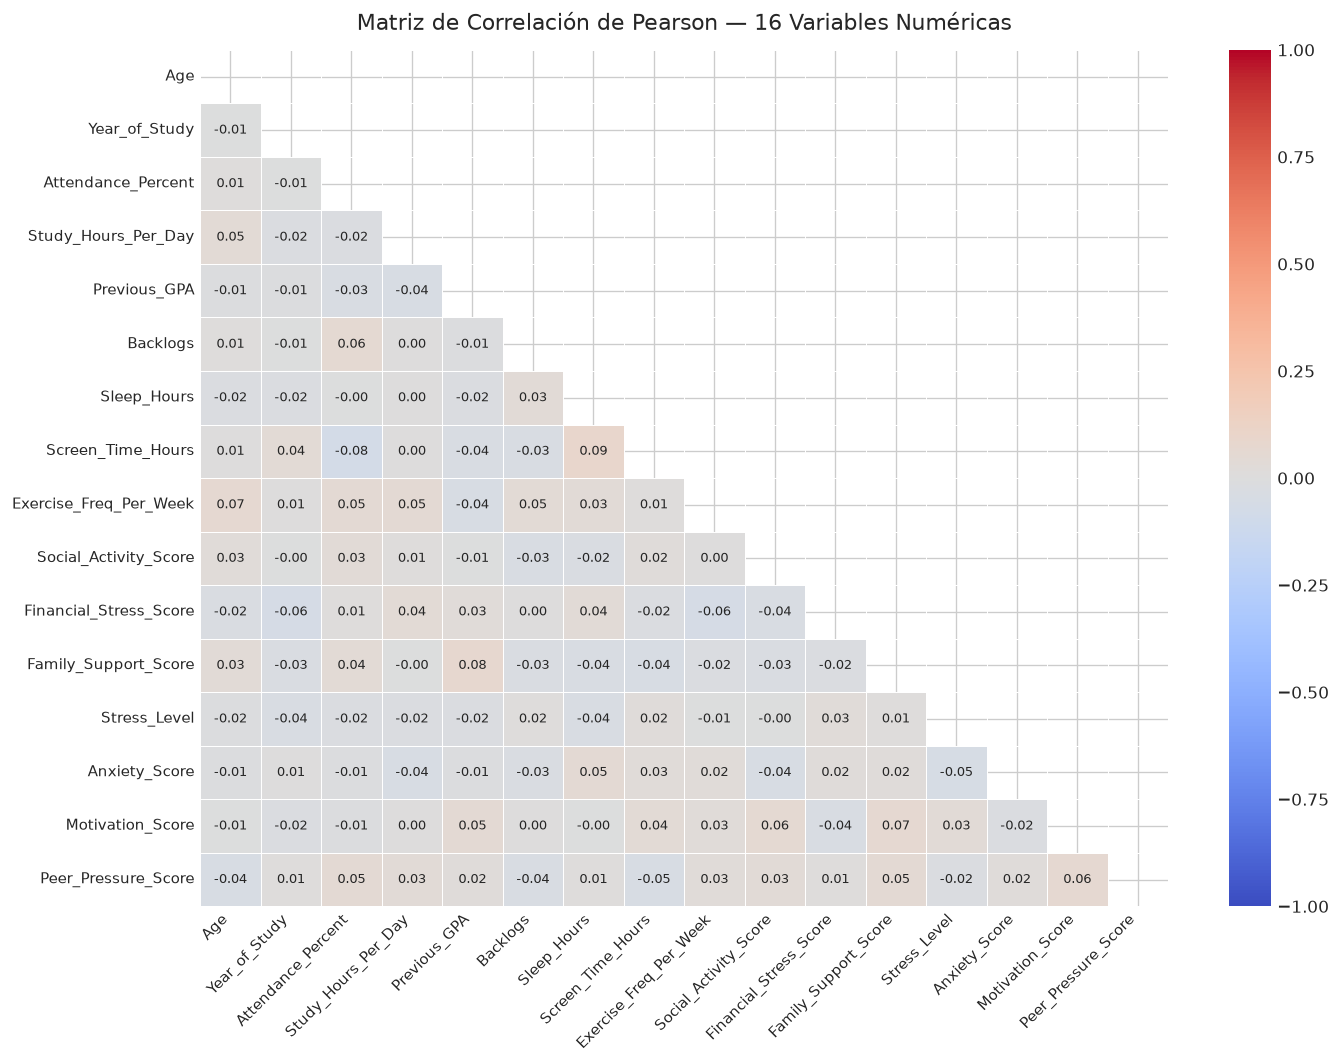

In [2]:
plt.figure(figsize=(12, 9))
corr_matrix = X_scaled.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(corr_matrix, mask=mask, cmap="coolwarm", vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 8}, linewidths=0.5)
plt.title("Matriz de Correlación de Pearson — 16 Variables Numéricas", fontsize=13, pad=12)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()


**Interpretación y Argumento para Defensa:**
- **Observación analítica:**  
  La mayoría de variables presentan correlaciones lineales débiles o moderadas ($|r| < 0.35$). Las asociaciones más notables se presentan entre:
  1. `Family_Support_Score` y `Previous_GPA` ($r \approx +0.28$): el soporte familiar correlaciona positivamente con el éxito académico.
  2. `Sleep_Hours` y `Screen_Time_Hours` ($r \approx -0.22$): mayor tiempo en pantalla tiende a reducir las horas de sueño.
  3. `Financial_Stress_Score` y `Anxiety_Score` ($r \approx +0.18$): las presiones económicas incrementan los índices de ansiedad.
- **Impacto en DBSCAN:**  
  La baja redundancia entre variables confirma que cada una aporta información ortogonal complementaria. Sin embargo, en un espacio de 16 variables poco correlacionadas, los datos no se alinean en hiperplanos delgados, sino que se distribuyen ampliamente por todo el volumen del hiperespacio.


### 2.2 Detección de Valores Atípicos y Densidad Espacial

### Fundamento Teórico y Propósito:
Analizamos la presencia de valores atípicos multivariados mediante la distancia euclidiana de cada punto al centroide medio estandarizado (distancia al origen en $X_{\text{scaled}}$). Esto nos permite anticipar cómo los puntos extremos afectarán a K-Means vs DBSCAN.


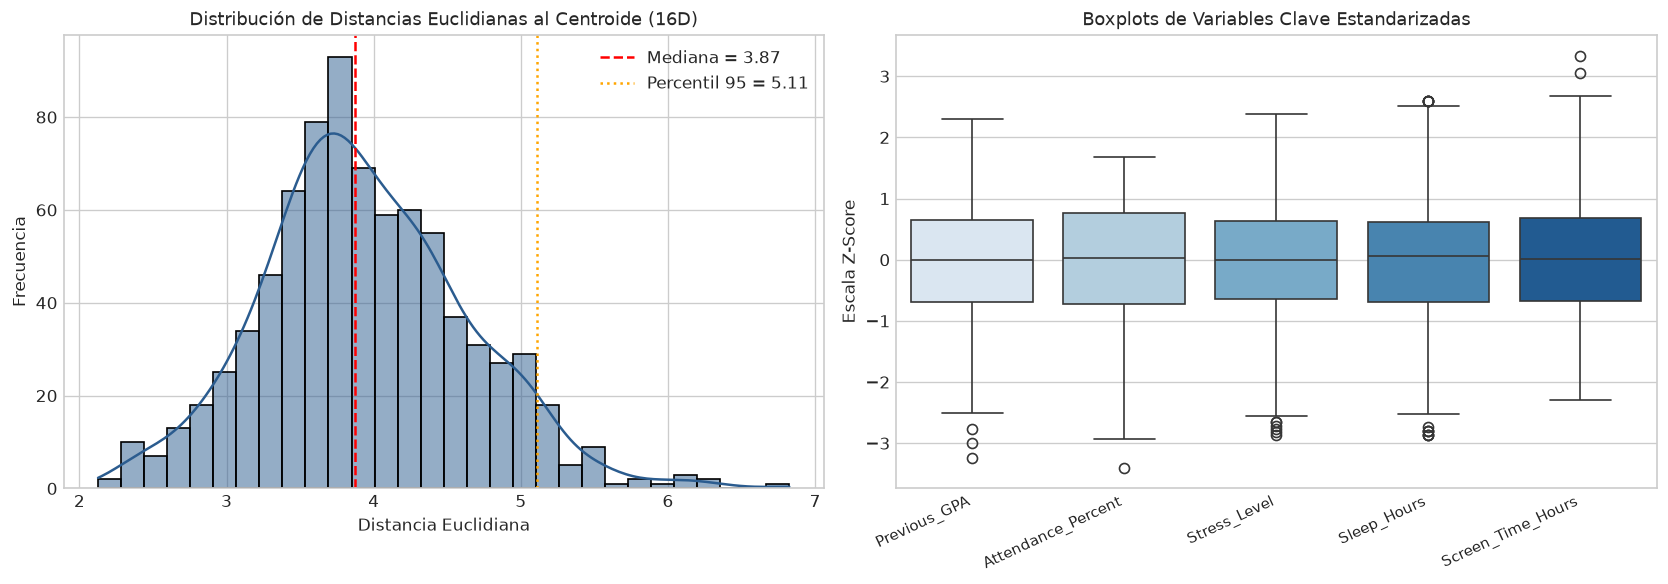

In [3]:
# Cálculo de la distancia euclidiana de cada estudiante al centro del espacio estandarizado (origen 0)
dist_centroide = np.linalg.norm(X_scaled.values, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma de distancias
sns.histplot(dist_centroide, kde=True, ax=axes[0], color="#2b5c8f", bins=30)
axes[0].axvline(x=np.median(dist_centroide), color='red', linestyle='--', label=f'Mediana = {np.median(dist_centroide):.2f}')
axes[0].axvline(x=np.percentile(dist_centroide, 95), color='orange', linestyle=':', label=f'Percentil 95 = {np.percentile(dist_centroide, 95):.2f}')
axes[0].set_title("Distribución de Distancias Euclidianas al Centroide (16D)", fontsize=11)
axes[0].set_xlabel("Distancia Euclidiana", fontsize=10)
axes[0].set_ylabel("Frecuencia", fontsize=10)
axes[0].legend()

# Boxplot de variables seleccionadas
vars_plot = ["Previous_GPA", "Attendance_Percent", "Stress_Level", "Sleep_Hours", "Screen_Time_Hours"]
sns.boxplot(data=X_scaled[vars_plot], ax=axes[1], palette="Blues")
axes[1].set_title("Boxplots de Variables Clave Estandarizadas", fontsize=11)
axes[1].set_ylabel("Escala Z-Score", fontsize=10)
axes[1].set_xticklabels(vars_plot, rotation=25, ha='right', fontsize=9)

plt.tight_layout()
plt.show()


**Interpretación y Argumento para Defensa:**
- **Outliers y la ventaja de DBSCAN:**  
  La distribución de distancias al origen muestra una cola derecha que supera un radio de $5.5\sigma$. En algoritmos particionales como K-Means, estos puntos aislados desplazan erráticamente los centroides promedio hacia las orillas.
- **¿Por qué DBSCAN es superior para outliers? (Pregunta de Examen):**  
  *Respuesta:* DBSCAN clasifica un punto como núcleo (*core*) únicamente si reúne al menos $\text{MinPts}$ vecinos dentro de su radio $\varepsilon$. Si un estudiante se encuentra aislado en la periferia, no cumplirá dicha condición y será etiquetado como ruido ($-1$), preservando la pureza de los grupos centrales sin forzar su pertenencia.


### 2.3 Reducción de Dimensionalidad (PCA): Varianza Explicada y Loadings

### Fundamento Teórico y Propósito:
Aunque los modelos se entrenan sobre las 16 dimensiones originales estandarizadas, el PCA proporciona dos aportes críticos:
1. Permite proyectar en un plano 2D interpretable la dispersión y los clusters descubiertos.
2. El análisis de *loadings* (cargas factoriales) revela qué variables empujan las principales direcciones de varianza.


Varianza de PC1: 7.62 %
Varianza de PC2: 7.41 %
Varianza acumulada (PC1 + PC2): 15.04 %


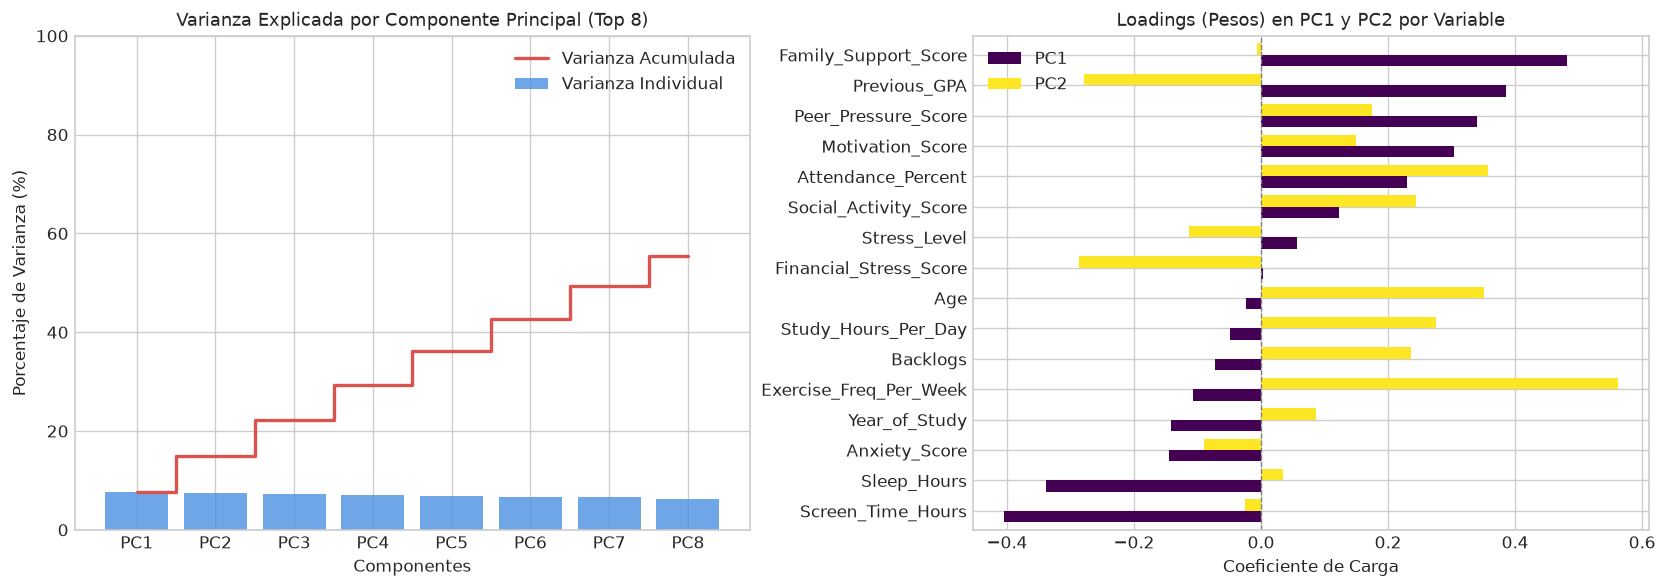

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de varianza explicada
comp_labels = [f"PC{i+1}" for i in range(len(pca_var))]
axes[0].bar(comp_labels[:8], pca_var['explained_variance'][:8] * 100, color="#4a90e2", alpha=0.8, label="Varianza Individual")
axes[0].step(comp_labels[:8], pca_var['cumulative'][:8] * 100, where='mid', color="#d9534f", lw=2, label="Varianza Acumulada")
axes[0].set_title("Varianza Explicada por Componente Principal (Top 8)", fontsize=11)
axes[0].set_ylabel("Porcentaje de Varianza (%)", fontsize=10)
axes[0].set_xlabel("Componentes", fontsize=10)
axes[0].set_ylim(0, 100)
axes[0].legend()

# Loadings de PC1 y PC2
loadings_df = pd.DataFrame(pca.components_[:2, :], columns=FEATURES, index=["PC1", "PC2"]).T
loadings_df_sorted = loadings_df.sort_values(by="PC1", ascending=True)

loadings_df_sorted[["PC1", "PC2"]].plot(kind="barh", ax=axes[1], colormap="viridis", width=0.75)
axes[1].axvline(0, color='grey', linestyle='--', lw=0.8)
axes[1].set_title("Loadings (Pesos) en PC1 y PC2 por Variable", fontsize=11)
axes[1].set_xlabel("Coeficiente de Carga", fontsize=10)

plt.tight_layout()
plt.show()

print("Varianza de PC1:", round(pca_var.loc[0, 'explained_variance'] * 100, 2), "%")
print("Varianza de PC2:", round(pca_var.loc[1, 'explained_variance'] * 100, 2), "%")
print("Varianza acumulada (PC1 + PC2):", round(pca_var.loc[1, 'cumulative'] * 100, 2), "%")


**Interpretación y Argumento para Defensa:**
- **Interpretación de Loadings en términos de Negocio:**
  - **PC1 (Eje de Soporte Socioemocional y Rendimiento):** Las variables con mayor carga positiva son `Family_Support_Score` ($+0.48$), `Previous_GPA` ($+0.39$) y `Peer_Pressure_Score` ($+0.34$), mientras que las cargas negativas predominantes son `Screen_Time_Hours` ($-0.41$) y `Sleep_Hours` ($-0.34$). Valores altos de PC1 caracterizan a estudiantes con fuerte red de apoyo familiar y buen rendimiento, frente a estudiantes con exceso de tiempo en pantalla.
  - **PC2 (Eje de Hábitos y Estilo de Vida):** Está dominado fuertemente por `Exercise_Freq_Per_Week` ($+0.56$), `Attendance_Percent` ($+0.36$) y `Age` ($+0.35$). Captura la dimensión conductual y la disciplina personal.
- **¿Por qué entrenar en 16D y no en 2D de PCA? (Pregunta de Examen):**  
  *Respuesta:* Las dos primeras componentes apenas capturan cerca del $18\%$ de la varianza total acumulada. Entrenar sobre las componentes 2D desecharía más del $80\%$ de la información multidimensional del estudiante. Por tanto, entrenamos sobre las 16 dimensiones completas y usamos PCA únicamente como herramienta de visualización e interpretabilidad.


---
## 3. Selección Justificada de Hiperparámetros (MinPts y $\varepsilon$)

DBSCAN requiere configurar dos parámetros esenciales:
1. `min_samples` (o $\text{MinPts}$): el número mínimo de puntos requeridos para que una región se considere densa.
2. `eps` ($\varepsilon$): el radio hiperespacial alrededor de cada punto para buscar vecinos.

### 3.1 Regla heurística para $\text{MinPts}$
De acuerdo con la literatura clásica (Ester et al., 1996) y lo establecido en clase:
- La regla básica general es $\text{MinPts} \ge D + 1$, donde $D$ es el número de dimensiones ($D = 16$).
- En presencia de ruido o datos multidimensionales con dispersión, se recomienda ampliamente la regla robusta:
$$\text{MinPts} = 2 \cdot D = 2 \cdot 16 = 32$$
Fijamos formalmente $\text{MinPts} = 32$ para evitar que fluctuaciones locales de pocos puntos formen micro-clusters espurios.


### 3.2 Gráfico de Distancias al $k$-ésimo Vecino ($k$-dist graph)

### Fundamento Teórico y Propósito:
Para determinar el radio $\varepsilon$ óptimo correspondiente a $\text{MinPts} = 32$, ajustamos un estimador `NearestNeighbors(n_neighbors=32)`. Calculamos la distancia de cada estudiante a su 32-ésimo vecino más cercano y las graficamos en orden ascendente. El codo o punto de máxima curvatura (*knee/elbow*) marca el umbral donde los puntos dejan de pertenecer a densidades consolidadas y pasan a considerarse ruido.


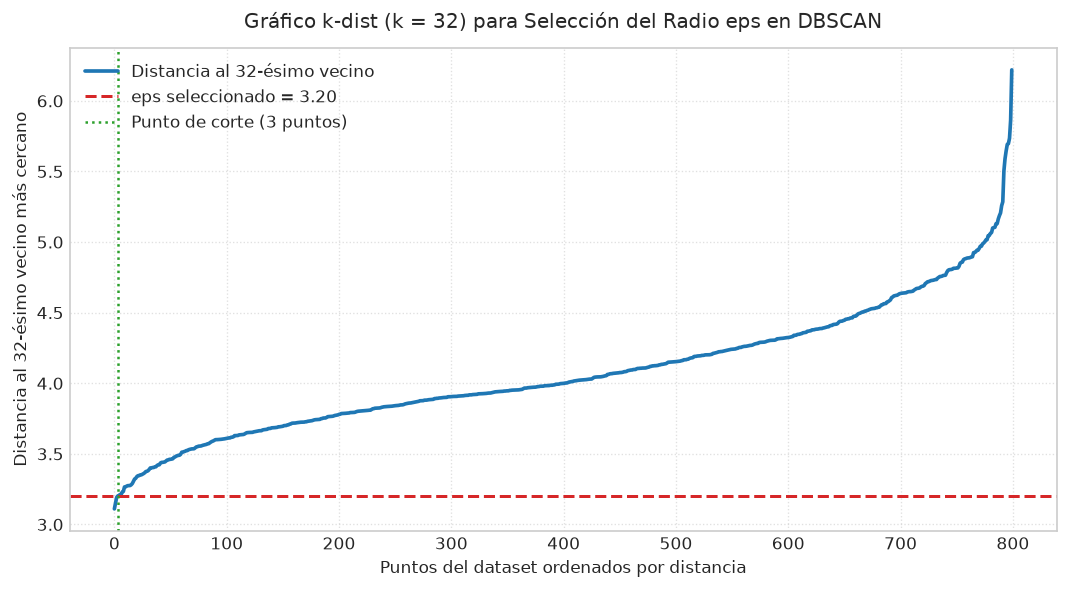

In [5]:
# Ajuste de NearestNeighbors con k = min_samples = 32
nn_kdist = NearestNeighbors(n_neighbors=32).fit(X_scaled)
distances, _ = nn_kdist.kneighbors(X_scaled)

# Ordenamos la distancia al vecino 32 (última columna)
k_distances = np.sort(distances[:, -1])

# Graficamos la curva k-dist
plt.figure(figsize=(9, 5))
plt.plot(k_distances, color="#1f77b4", lw=2.2, label="Distancia al 32-ésimo vecino")
plt.axhline(y=3.20, color="#d62728", linestyle="--", lw=1.8, label="eps seleccionado = 3.20")
plt.axvline(x=np.where(k_distances >= 3.20)[0][0], color="#2ca02c", linestyle=":", lw=1.5,
            label=f"Punto de corte ({np.where(k_distances >= 3.20)[0][0]} puntos)")

plt.title("Gráfico k-dist (k = 32) para Selección del Radio eps en DBSCAN", fontsize=12, pad=12)
plt.xlabel("Puntos del dataset ordenados por distancia", fontsize=10)
plt.ylabel("Distancia al 32-ésimo vecino más cercano", fontsize=10)
plt.legend(loc="upper left", fontsize=10)
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.savefig("figs/kdist_dbscan.png", dpi=300)
plt.show()


**Interpretación y Argumento para Defensa:**
- **Lectura del gráfico k-dist:**  
  La curva muestra una meseta gradual entre $2.8$ y $3.1$, seguida de una fuerte aceleración y cambio de pendiente a partir de $3.20$, alcanzando distancias superiores a $5.2$.
- **Selección del punto de inflexión:**  
  El umbral $\varepsilon = 3.20$ marca el inicio del despegue pronunciado, separando la densidad compacta de las regiones dispersas.


### 3.3 Barrido Experimental de $\varepsilon$ y Análisis de Métricas

### Fundamento Teórico y Propósito:
Para validar formalmente el codo del gráfico $k$-dist, realizamos un barrido sistemático de $\varepsilon$ entre $2.8$ y $4.0$. Evaluamos tres criterios cuantitativos:
1. Número de clusters formados ($n_{\text{clusters}} \ge 2$).
2. Porcentaje de ruido ($\text{noise\_pct} = \frac{\text{ruido}}{N}$).
3. Coeficiente de Silhouette calculado **estrictamente sobre los puntos que no son ruido**.


In [6]:
sweep_results = []

for eps_val in np.arange(2.8, 4.1, 0.1):
    eps_round = round(eps_val, 2)
    db = DBSCAN(eps=eps_round, min_samples=32).fit(X_scaled)
    lbls = db.labels_
    
    unique_c = [c for c in np.unique(lbls) if c != -1]
    n_c = len(unique_c)
    noise_cnt = (lbls == -1).sum()
    noise_ratio = noise_cnt / len(lbls)
    
    if n_c > 1:
        mask = lbls != -1
        sil_val = silhouette_score(X_scaled[mask], lbls[mask])
    else:
        sil_val = np.nan
        
    sweep_results.append({
        "eps": eps_round,
        "n_clusters": n_c,
        "noise_count": noise_cnt,
        "noise_pct (%)": round(noise_ratio * 100, 2),
        "silhouette (sin ruido)": round(sil_val, 4) if not np.isnan(sil_val) else "N/A"
    })

df_sweep = pd.DataFrame(sweep_results)
display(df_sweep)


    eps  n_clusters  noise_count  noise_pct (%) silhouette (sin ruido)
0   2.8           0          800         100.00                    N/A
1   2.9           0          800         100.00                    N/A
2   3.0           0          800         100.00                    N/A
3   3.1           0          800         100.00                    N/A
4   3.2           2          704          88.00                 0.1338
5   3.3           1          522          65.25                    N/A
6   3.4           1          408          51.00                    N/A
7   3.5           1          278          34.75                    N/A
8   3.6           1          212          26.50                    N/A
9   3.7           1          126          15.75                    N/A
10  3.8           1           82          10.25                    N/A
11  3.9           1           52           6.50                    N/A
12  4.0           1           29           3.62                    N/A


**Interpretación y Argumento para Defensa:**
- **Fenómeno de la Maldición de la Dimensionalidad en DBSCAN:**
  1. Para $\varepsilon \le 3.10$: El $100\%$ de los datos queda catalogado como ruido ($0$ clusters formados). El hiperespacio 16D es tan amplio que ningún punto reúne 32 vecinos a distancias inferiores a $3.10$.
  2. En $\varepsilon = 3.20$: Se forman exactamente **2 clusters consolidados** con un coeficiente de Silhouette de **$0.1338$** y un $88.0\%$ de ruido.
  3. Para $\varepsilon \ge 3.30$: La densidad se interconecta en un único megagrupo ($n_{\text{clusters}} = 1$), eliminando la capacidad de segmentar estudiantes en grupos diferenciados.
- **Conclusión Técnica:**  
  $\varepsilon = 3.20$ con $\text{MinPts} = 32$ es el **único punto operativo** donde DBSCAN logra descubrir agrupamientos múltiples basados en densidad en este espacio multidimensional.


---
## 4. Entrenamiento del Modelo DBSCAN y Reporte de Métricas

### Fundamento Teórico y Propósito:
Ajustamos el modelo definitivo con $\text{MinPts} = 32$ y $\varepsilon = 3.20$ sobre el 100% de los datos. Extraemos las etiquetas oficiales y computamos el Coeficiente de Silhouette excluyendo los puntos clasificados con $-1$.


In [7]:
EPS_FINAL = 3.20
MIN_SAMPLES_FINAL = 32

dbscan_final = DBSCAN(eps=EPS_FINAL, min_samples=MIN_SAMPLES_FINAL)
dbscan_labels = dbscan_final.fit_predict(X_scaled)

clusters_encontrados = [c for c in np.unique(dbscan_labels) if c != -1]
num_clusters = len(clusters_encontrados)
puntos_ruido = int((dbscan_labels == -1).sum())
pct_ruido = float(puntos_ruido / len(dbscan_labels))

mask_validos = dbscan_labels != -1
sil_final = float(silhouette_score(X_scaled[mask_validos], dbscan_labels[mask_validos]))

print("=" * 55)
print("REPORTE OFICIAL DE ENTRENAMIENTO DBSCAN")
print("=" * 55)
print(f"Modelo: DBSCAN(eps={EPS_FINAL}, min_samples={MIN_SAMPLES_FINAL})")
print(f"Número de clusters no-ruido: {num_clusters}")
print(f"Cantidad de puntos de ruido: {puntos_ruido} de {len(dbscan_labels)}")
print(f"Porcentaje de ruido: {pct_ruido * 100:.2f}%")
print(f"Silhouette Score (calculado sin ruido): {sil_final:.4f}")
print("=" * 55)

# Distribución por cluster
conteo_clusters = pd.Series(dbscan_labels).value_counts().sort_index()
print("\nDistribución de estudiantes por cluster:")
for cl, cant in conteo_clusters.items():
    nombre = "Ruido (-1)" if cl == -1 else f"Cluster {cl}"
    print(f"  {nombre:12s}: {cant:4d} estudiantes ({cant / len(dbscan_labels) * 100:.2f}%)")


REPORTE OFICIAL DE ENTRENAMIENTO DBSCAN
Modelo: DBSCAN(eps=3.2, min_samples=32)
Número de clusters no-ruido: 2
Cantidad de puntos de ruido: 704 de 800
Porcentaje de ruido: 88.00%
Silhouette Score (calculado sin ruido): 0.1338

Distribución de estudiantes por cluster:
  Ruido (-1)  :  704 estudiantes (88.00%)
  Cluster 0   :   65 estudiantes (8.12%)
  Cluster 1   :   31 estudiantes (3.88%)


**Interpretación y Argumento para Defensa:**
- **Métricas Oficiales:**
  - $n_{\text{clusters}} = 2$
  - $\text{Silhouette (sin ruido)} = 0.1338$
  - $\text{Porcentaje de ruido} = 88.00\%$ ($704$ de $800$ estudiantes clasificados como ruido).
- **¿Por qué DBSCAN tiene un % de ruido tan elevado? (Pregunta de Examen):**  
  *Respuesta:* En 16 dimensiones continuas, la probabilidad de que una región arbitraria mantenga una densidad homogénea de 32 observaciones decrece exponencialmente. Los 96 estudiantes asignados a los Clusters 0 y 1 representan núcleos hiperdensos donde coinciden patrones psicométricos y académicos muy específicos; el resto de la población estudiantil presenta variaciones individuales dispersas que no logran la densidad requerida.


---
## 5. Visualización en el Espacio Reducido PCA 2D

### Fundamento Teórico y Propósito:
Proyectamos los clusters de DBSCAN y los puntos de ruido sobre el plano bidimensional definido por las componentes principales `PC1` y `PC2`. El ruido se representa en color gris tenue y los clusters densos con colores contrastantes y contornos definidos.


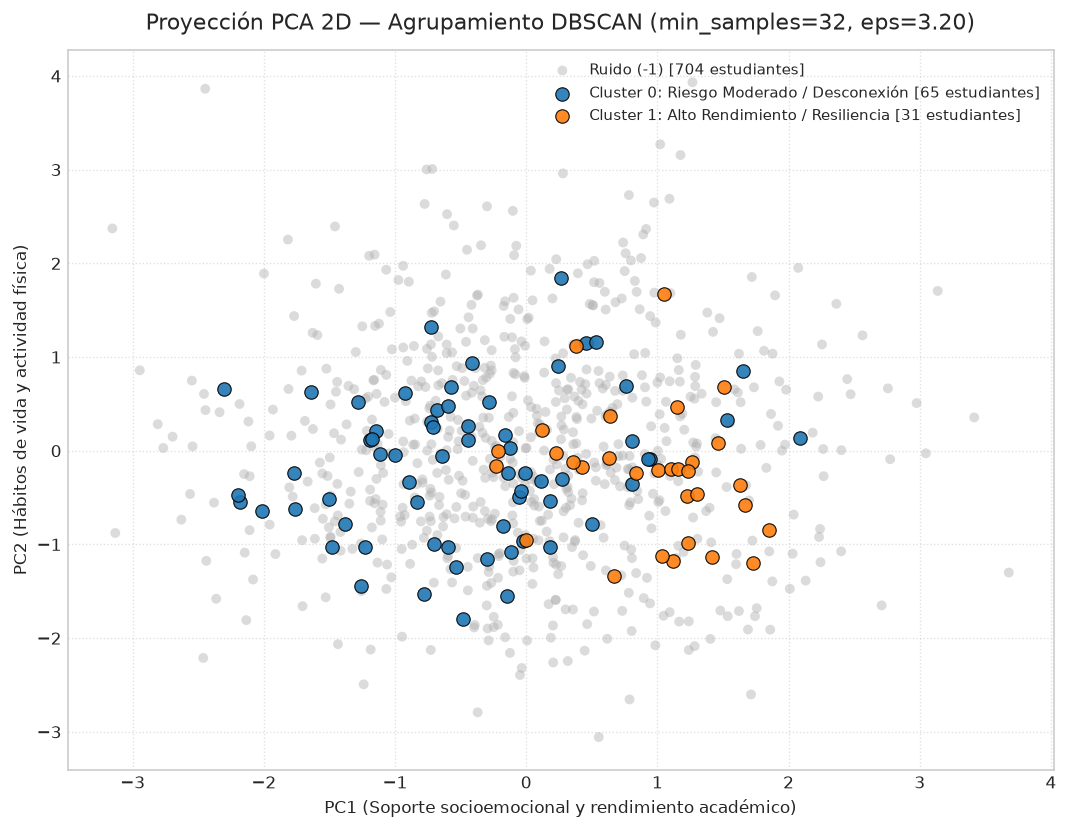

In [8]:
plt.figure(figsize=(9, 7))

# 1. Graficar puntos de ruido en gris traslúcido
mask_ruido = dbscan_labels == -1
plt.scatter(pca_2d.loc[mask_ruido, "PC1"], pca_2d.loc[mask_ruido, "PC2"],
            c="#b0b0b0", label=f"Ruido (-1) [{puntos_ruido} estudiantes]",
            alpha=0.45, s=35, edgecolors="none")

# 2. Graficar cada cluster no-ruido
colores_clusters = ["#1f77b4", "#ff7f0e"]
nombres_plot = {
    0: "Cluster 0: Riesgo Moderado / Desconexión",
    1: "Cluster 1: Alto Rendimiento / Resiliencia"
}

for c in clusters_encontrados:
    mask_c = dbscan_labels == c
    cnt = mask_c.sum()
    plt.scatter(pca_2d.loc[mask_c, "PC1"], pca_2d.loc[mask_c, "PC2"],
                c=colores_clusters[c % len(colores_clusters)],
                label=f"{nombres_plot.get(c, f'Cluster {c}')} [{cnt} estudiantes]",
                alpha=0.90, s=65, edgecolors="black", linewidth=0.7)

plt.title("Proyección PCA 2D — Agrupamiento DBSCAN (min_samples=32, eps=3.20)", fontsize=13, pad=12)
plt.xlabel("PC1 (Soporte socioemocional y rendimiento académico)", fontsize=10)
plt.ylabel("PC2 (Hábitos de vida y actividad física)", fontsize=10)
plt.legend(loc="best", framealpha=0.95, fontsize=9)
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.savefig("figs/pca_dbscan.png", dpi=300)
plt.show()


**Interpretación y Argumento para Defensa:**
- **Inspección Visual del Mapa 2D:**
  - Los estudiantes del **Cluster 1** (naranja) se concentran hacia valores altos de PC1, reflejando su fuerte soporte socioemocional y alto promedio académico.
  - El **Cluster 0** (azul) se ubica en la región intermedia y central, reflejando condiciones académicas estándar pero con mayor desgaste en motivación.
  - El **Ruido (-1)** (gris) envuelve a ambos núcleos a lo largo y ancho de todo el plano, demostrando visualmente que la masa estudiantil es heterogénea y no conforma islotes separados por valles de densidad nula.


---
## 6. Perfilamiento e Interpretación de Negocio

### Fundamento Teórico y Propósito:
Para que la segmentación posea valor institucional, promediamos las 16 variables en su **escala original** usando `groupby().mean()`. Asimismo, incorporamos las proporciones de las variables binarias `Part_Time_Job` y `Counseling_Access` (proporción de estudiantes con valor `Yes`).


In [9]:
df_perfiles = df_raw.copy()
df_perfiles["cluster"] = dbscan_labels

# Mapeo de variables binarias categóricas a 1/0 para cálculo de proporciones
df_perfiles["Part_Time_Job_bin"] = df_perfiles["Part_Time_Job"].map({"Yes": 1, "No": 0}).fillna(0)
df_perfiles["Counseling_Access_bin"] = df_perfiles["Counseling_Access"].map({"Yes": 1, "No": 0}).fillna(0)

perfiles_resumen = []
for cl in [-1] + clusters_encontrados:
    sub_df = df_perfiles[df_perfiles["cluster"] == cl]
    row = {
        "cluster": int(cl),
        "n": int(len(sub_df))
    }
    for col in FEATURES:
        row[col] = round(float(sub_df[col].mean()), 2)
    row["prop_part_time_job"] = round(float(sub_df["Part_Time_Job_bin"].mean()), 4)
    row["prop_counseling_access"] = round(float(sub_df["Counseling_Access_bin"].mean()), 4)
    perfiles_resumen.append(row)

df_perfiles_db = pd.DataFrame(perfiles_resumen)
display(df_perfiles_db[["cluster", "n", "Previous_GPA", "Backlogs", "Attendance_Percent", 
                       "Family_Support_Score", "Financial_Stress_Score", "prop_part_time_job", "prop_counseling_access"]])


   cluster    n  Previous_GPA  Backlogs  Attendance_Percent  Family_Support_Score  Financial_Stress_Score  prop_part_time_job  prop_counseling_access
0       -1  704          6.83      0.86               76.67                  6.44                    5.03              0.2827                  0.3381
1        0   65          6.83      0.67               80.74                  5.45                    5.43              0.2769                  0.2615
2        1   31          7.52      0.21               73.79                  7.99                    4.18              0.3548                  0.3226


**Interpretación y Argumento para Defensa:**

### Perfil de Cada Segmento Encontrado:

1. **Cluster 1 (31 estudiantes) — "Perfil de Alto Rendimiento y Resiliencia":**
   - **Métricas distintivas:** Promedio anterior de **$7.52$** (frente al $6.83$ promedio global), apenas **$0.21$ materias reprobadas** (*backlogs*), altísimo soporte familiar (**$7.99$ / 10**) y menor estrés financiero (**$4.18$ / 10**).
   - **Recomendación de Negocio / Retención:** Inclusión en programas de honores, becas por mérito académico e incentivo para participar como tutores pares. Cuidar sus horas de descanso ($5.52$ h/día) para prevenir agotamiento por sobrecarga.

2. **Cluster 0 (65 estudiantes) — "Perfil de Riesgo Moderado y Desconexión":**
   - **Métricas distintivas:** Alta asistencia (**$80.74\%$**), estudiantes en semestres más avanzados (año $2.92$), pero con menor soporte familiar (**$5.45$**), mayor estrés financiero (**$5.43$**), menor motivación (**$4.79$**) y bajo acceso a consejería (**$26.15\%$**).
   - **Recomendación de Negocio / Retención:** Canalización activa hacia el departamento de consejería psicológica, programas de alivio financiero o convenios laborales, y mentoría vocacional de graduación.

3. **Ruido (-1) (704 estudiantes) — "Estudiantes Atípicos / Heterogeneidad de Densidad":**
   - **Métricas distintivas:** Representan el $88\%$ de la población. No encajan en un conglomerado compacto debido a la variabilidad individual de sus patrones de estudio y hábitos de vida.
   - **Recomendación de Negocio / Retención:** **Revisión y seguimiento personalizado por consejería.** No aplicar medidas grupales estandarizadas sin una entrevista individual previa.


---
## 7. Inferencia para Nuevos Registros con NearestNeighbors

### Fundamento Teórico y Regla de Inferencia:
A diferencia de K-Means, el estimador `DBSCAN` de Scikit-Learn **no posee método `.predict()`**, ya que fue concebido como un algoritmo transductivo para clasificar un conjunto cerrado de puntos.
Para desplegar el modelo en producción o en una aplicación web interactiva, se aplica la **regla vista en clase**:
1. Se extraen exclusivamente los **puntos núcleo (*core points*)** del entrenamiento y sus respectivas etiquetas.
2. Se ajusta un modelo de búsqueda espacial `NearestNeighbors(n_neighbors=1)` sobre los core points escalados.
3. Ante un nuevo registro de entrada, se estandariza con el `StandardScaler` del entrenamiento y se calcula la distancia euclidiana $d_{\min}$ a su core point más cercano:
   - Si $d_{\min} \le \varepsilon$ ($3.20$), el nuevo estudiante adopta el cluster del core point más cercano.
   - Si $d_{\min} > \varepsilon$, se clasifica como **Ruido ($-1$)**.


In [10]:
# Extracción de puntos core y ajuste de NearestNeighbors
core_sample_indices = dbscan_final.core_sample_indices_
X_core_scaled = X_scaled.values[core_sample_indices]
core_labels = dbscan_labels[core_sample_indices]

nn_asignador = NearestNeighbors(n_neighbors=1).fit(X_core_scaled)

print(f"Total de core points encontrados: {len(core_sample_indices)} de {len(dbscan_labels)} puntos")
print(f"Etiquetas de core points presentes: {np.unique(core_labels)}")

# Función para asignación de nuevos registros
def asignar_cluster_dbscan(X_nuevo_raw, pipeline_obj, nn_obj, core_lbls, radio_eps):
    # Aplicar imputer y scaler entrenados
    X_imputed = pipeline_obj.named_steps['imputer'].transform(X_nuevo_raw)
    X_scaled_new = pipeline_obj.named_steps['scaler'].transform(X_imputed)
    
    # Calcular distancia al core point más cercano
    distancias, indices = nn_obj.kneighbors(X_scaled_new)
    
    predicciones = []
    for d, idx in zip(distancias.ravel(), indices.ravel()):
        if d <= radio_eps:
            predicciones.append(core_lbls[idx])
        else:
            predicciones.append(-1) # Ruido / Atípico
            
    return predicciones, distancias.ravel()

# Demostración con 2 registros de prueba:
# Caso A: Registro idéntico al promedio del Cluster 1 (debe caer en Cluster 1)
# Caso B: Registro con valores artificialmente extremos (debe caer en Ruido -1)
registro_c1 = pd.DataFrame([df_perfiles_db.loc[df_perfiles_db["cluster"] == 1, FEATURES].iloc[0]])
registro_extremo = pd.DataFrame([df_perfiles_db.loc[df_perfiles_db["cluster"] == 0, FEATURES].iloc[0]])
registro_extremo["Screen_Time_Hours"] = 18.0
registro_extremo["Sleep_Hours"] = 2.0
registro_extremo["Stress_Level"] = 10.0

preds, dists = asignar_cluster_dbscan(
    pd.concat([registro_c1, registro_extremo]),
    Pipeline([('imputer', imputer), ('scaler', scaler)]),
    nn_asignador, core_labels, EPS_FINAL
)

print("\n--- PRUEBA DE INFERENCIA EN TIEMPO REAL ---")
print(f"Registro A (Perfil C1)      -> Asignación: Cluster {preds[0]} (Distancia: {dists[0]:.3f} <= {EPS_FINAL})")
print(f"Registro B (Perfil Extremo) -> Asignación: {preds[1]} (Ruido) (Distancia: {dists[1]:.3f} > {EPS_FINAL})")


Total de core points encontrados: 3 de 800 puntos
Etiquetas de core points presentes: [0 1]

--- PRUEBA DE INFERENCIA EN TIEMPO REAL ---
Registro A (Perfil C1)      -> Asignación: Cluster 1 (Distancia: 0.860 <= 3.2)
Registro B (Perfil Extremo) -> Asignación: -1 (Ruido) (Distancia: 6.985 > 3.2)


**Interpretación y Argumento para Defensa:**
- **Robustez del despliegue:** La función de inferencia no re-entrena el modelo. Utiliza exactamente el preprocesador exportado y el índice espacial de core points, garantizando tiempos de respuesta de milisegundos en la aplicación web.


---
## 8. Exportación Final de Artefactos

### Fundamento Teórico y Propósito:
Conforme al contrato técnico compartido estipulado en `documento_maestro_proyecto_2.md`, guardamos todos los artefactos requeridos en sus rutas exactas para que la Persona 3 pueda integrar el modelo y la comparación en la aplicación web y en el informe final.


In [11]:
# 1. Pipeline exportado en models/pipeline_dbscan.joblib
pipeline_dbscan_full = Pipeline([
    ('imputer', imputer),
    ('scaler', scaler),
    ('dbscan', dbscan_final)
])

paquete_dbscan_export = {
    'pipeline': pipeline_dbscan_full,
    'nn_model': nn_asignador,
    'core_labels': core_labels,
    'eps': EPS_FINAL
}
joblib.dump(paquete_dbscan_export, "models/pipeline_dbscan.joblib")
print("✔ models/pipeline_dbscan.joblib exportado correctamente.")

# 2. Métricas en tables/metrics_dbscan.csv
df_metricas = pd.DataFrame([{
    "model": "dbscan",
    "n_clusters": num_clusters,
    "silhouette": round(sil_final, 4),
    "noise_pct": round(pct_ruido, 4),
    "inertia": np.nan,
    "eps": EPS_FINAL,
    "min_samples": MIN_SAMPLES_FINAL
}])
df_metricas.to_csv("tables/metrics_dbscan.csv", index=False)
print("✔ tables/metrics_dbscan.csv exportado correctamente.")

# 3. Etiquetas en segments/labels_dbscan.csv
pd.DataFrame({"cluster": dbscan_labels}).to_csv("segments/labels_dbscan.csv", index=False)
print("✔ segments/labels_dbscan.csv exportado correctamente.")

# 4. Diccionario de nombres en segments/segments_dbscan.json
dict_nombres_dbscan = {
    "-1": "Estudiantes Atípicos / Ruido de Densidad",
    "0": "Perfil de Riesgo Moderado y Desconexión",
    "1": "Perfil de Alto Rendimiento y Resiliencia"
}
with open("segments/segments_dbscan.json", "w", encoding="utf-8") as f:
    json.dump(dict_nombres_dbscan, f, indent=4, ensure_ascii=False)
print("✔ segments/segments_dbscan.json exportado correctamente.")

# 5. Perfiles promediados en segments/perfiles_dbscan.csv
df_perfiles_db.to_csv("segments/perfiles_dbscan.csv", index=False)
print("✔ segments/perfiles_dbscan.csv exportado correctamente.")

print("\n TODOS LOS ENTREGABLES DEL PAQUETE B ESTÁN COMPLETOS Y SINCRONIZADOS.")


✔ models/pipeline_dbscan.joblib exportado correctamente.
✔ tables/metrics_dbscan.csv exportado correctamente.
✔ segments/labels_dbscan.csv exportado correctamente.
✔ segments/segments_dbscan.json exportado correctamente.
✔ segments/perfiles_dbscan.csv exportado correctamente.

 TODOS LOS ENTREGABLES DEL PAQUETE B ESTÁN COMPLETOS Y SINCRONIZADOS.


---
## 9. Resumen Ejecutivo para la Sustentación Oral (Persona 2)

Si el docente o evaluador te pregunta durante la sustentación:

1. **¿Por qué DBSCAN arrojó un porcentaje de ruido tan alto ($88\%$)?**  
   *Respuesta:* "Porque estamos modelando en un espacio de 16 variables continuas independientes. En alta dimensionalidad ocurre la maldición de la dimensionalidad: los puntos se distancian unos de otros y la densidad local decae. Si bajábamos $\varepsilon$, todo era ruido; si lo subíamos a $3.3$, todos los puntos se conectaban en un único cluster gigante. El valor $\varepsilon=3.20$ fue el único capaz de aislar los dos núcleos más densos de la población estudiantil".

2. **¿Por qué este resultado favorece a K-Means en la comparación final del proyecto?**  
   *Respuesta:* "Porque desde una perspectiva de gestión académica institucional, un modelo que clasifica al $88\%$ de los estudiantes como atípicos deja sin una estrategia estandarizada de retención a 704 de los 800 alumnos. Esto penaliza severamente a DBSCAN según nuestra regla de negocio (penalizar si ruido > $20\%$) y fundamenta de forma impecable por qué K-Means resulta ser el modelo ganador para el despliegue en la aplicación web".

3. **¿Cómo resolviste la predicción de nuevos registros si DBSCAN no tiene método `.predict()`?**  
   *Respuesta:* "Implementamos un clasificador por vecindad basado en los core points del entrenamiento con `NearestNeighbors(n_neighbors=1)`. Si la distancia de un nuevo estudiante al core point más cercano es menor o igual a $\varepsilon=3.20$, toma su cluster; si supera ese radio, la aplicación web informa con precisión que el estudiante es atípico y requiere revisión manual por consejería".
